<a href="https://colab.research.google.com/github/uzairbaig8110-cloud/CSL701-02-Machine-Learning-Lab/blob/main/experiments/ML_Experiment_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

###  ML Experiment Number 9
Student Name :Uzair I Baig

Batch :CS1


Roll Number :CS11



### **Aim**

To implement Classification and Regression Trees (CART) using Python on the Palmer Penguins Dataset Extended.

## Objectives

1. To understand the concept and working of the CART algorithm.
2. To implement Decision Tree Classification using Python.   
3. To visualize the constructed Decision Tree structure and decision boundaries.   
4. To analyze impurity measures such as Gini Index and Entropy.
5. To compare the decision boundary of a Decision Tree with a linear classification boundary (e.g., Logistic Regression).   
6. To evaluate and compare the performance of both classifiers.

# Relevant Theory

###Classification and Regression Trees (CART)
CART is a non-parametric supervised machine learning algorithm used for both classification and regression tasks. It builds a binary decision tree by recursively splitting the dataset based on feature values that maximize information gain or minimize impurity.

A tree consists of:

* Root Node: The topmost node representing the entire dataset.

* Internal Nodes: Decision points based on feature splits.

* Leaf/Terminal Nodes: Output class labels or predictions.

Impurity MeasuresGini Index (Gini Impurity): Measures the frequency with which a randomly chosen element from the set would be incorrectly labeled.$$Gini(D) = 1 - \sum_{i=1}^{k} p_i^2$$where $p_i$ is the probability of an item belonging to class $i$.Entropy & Information Gain: Measures the amount of impurity or randomness in the data.$$Entropy(D) = -\sum_{i=1}^{k} p_i \log_2(p_i)$$Dataset InformationGet the Palmer Penguins Dataset Extended from Kaggle using the following link:https://www.kaggle.com/datasets/samybaladram/palmers-penguin-dataset-extended The Palmer Penguins dataset contains measurements of penguin species across islands in the Palmer Archipelago:AdelieChinstrapGentooThe primary numerical features are:culmen_length_mm (or bill_length_mm)culmen_depth_mm (or bill_depth_mm)flipper_length_mmbody_mass_gFor visualization, we will use: culmen_length_mm and flipper_length_mm.

# Task 1: Import Libraries and Load Dataset
* Load essential libraries (numpy, pandas, matplotlib, seaborn, sklearn).

* Load the Palmer Penguins Extended dataset.
---

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.preprocessing import LabelEncoder

# Load the Palmer Penguins dataset from a reliable public repository
url = "https://raw.githubusercontent.com/mcnakhaee/palmerpenguins/master/palmerpenguins/data/penguins.csv"
penguins_df = pd.read_csv(url)

# Display the first few rows of the dataset
display(penguins_df.head())

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


# Task 2: Select Features and Target & Preprocess

* Handle missing values (e.g., drop rows with missing values or impute with median).   
* Select features ($X$) such as culmen_length_mm, culmen_depth_mm, flipper_length_mm, body_mass_g and set species as the target label ($y$).   
* Encode categorical targets if necessary using LabelEncoder.

In [2]:
# Task 2: Select Features and Target & Preprocess

# Check for missing values
print("Missing values before cleaning:")
print(penguins_df.isnull().sum())

# Drop rows with missing values in key features
features = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']
target = 'species'

penguins_cleaned = penguins_df.dropna(subset=features + [target]).copy()

# Select features (X) and target (y)
X = penguins_cleaned[features]
y = penguins_cleaned[target]

# Encode categorical target using LabelEncoder
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

print(f"\nProcessed Dataset Shape: {X.shape}")
print("Target Classes mapped:", dict(zip(label_encoder.classes_, range(len(label_encoder.classes_)))))

Missing values before cleaning:
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
year                  0
dtype: int64

Processed Dataset Shape: (342, 4)
Target Classes mapped: {'Adelie': 0, 'Chinstrap': 1, 'Gentoo': 2}


# Task 3: Split the Data

* Divide the dataset into training and testing sets using train_test_split.

In [3]:
# Task 3: Split the Data

X_train, X_test, y_train, y_test = train_test_split(X, y_encoded, test_size=0.3, random_state=42, stratify=y_encoded)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Training set shape: (239, 4)
Testing set shape: (103, 4)


# Task 4: Implement CART Classifier

* Create a DecisionTreeClassifier model using the Gini criterion (or Entropy).   
* Fit the model on the training data and make predictions on the test set.   

In [4]:
# Task 4: Implement CART Classifier

# Instantiate Decision Tree Classifier with Gini criterion
cart_model = DecisionTreeClassifier(criterion='gini', random_state=42, max_depth=4)

# Fit the model on training data
cart_model.fit(X_train, y_train)

# Predict on the test set
y_pred_cart = cart_model.predict(X_test)
print("Predictions completed successfully.")

Predictions completed successfully.


# Task 5: Evaluate CART Model

* Accuracy: Calculate classification accuracy.   
* Confusion Matrix: Generate the matrix to analyze misclassifications across species.
* Classification Report: Output Precision, Recall, F1-Score, and Support.   

CART Classifier Accuracy: 0.9903



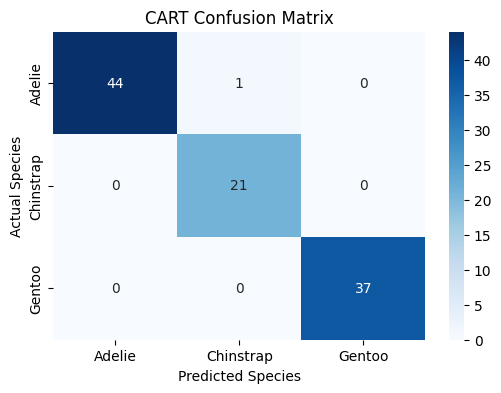

Classification Report:
              precision    recall  f1-score   support

      Adelie       1.00      0.98      0.99        45
   Chinstrap       0.95      1.00      0.98        21
      Gentoo       1.00      1.00      1.00        37

    accuracy                           0.99       103
   macro avg       0.98      0.99      0.99       103
weighted avg       0.99      0.99      0.99       103



In [5]:
# Task 5: Evaluate CART Model

# Calculate accuracy
accuracy_cart = accuracy_score(y_test, y_pred_cart)
print(f"CART Classifier Accuracy: {accuracy_cart:.4f}\n")

# Confusion Matrix
cm_cart = confusion_matrix(y_test, y_pred_cart)
plt.figure(figsize=(6, 4))
sns.heatmap(cm_cart, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.title('CART Confusion Matrix')
plt.ylabel('Actual Species')
plt.xlabel('Predicted Species')
plt.show()

# Classification Report
print("Classification Report:")
print(classification_report(y_test, y_pred_cart, target_names=label_encoder.classes_))

# Task 6: Visualize Decision Tree & Decision Boundary

* Visualize Tree Structure: Plot the decision tree diagram using sklearn.tree.plot_tree.
* Select 2-D Features: Select culmen_length_mm and flipper_length_mm.   
* Train 2-D Model & Plot Boundary: Train the decision tree on 2D data and plot axis-aligned rectangular decision boundaries along with data points


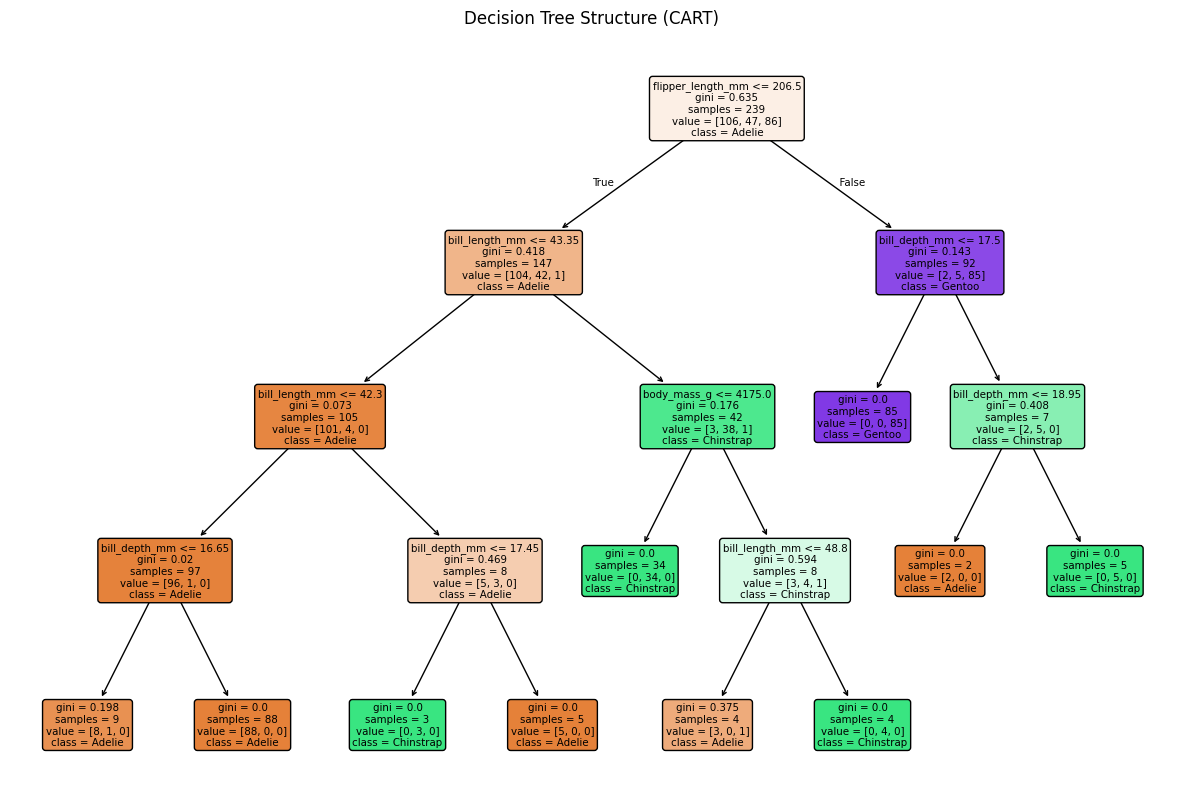

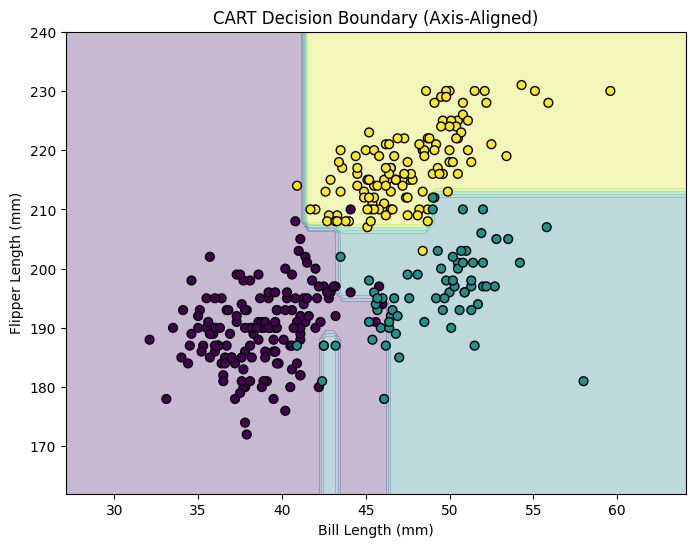

In [6]:
# Task 6: Visualize Decision Tree & Decision Boundary

# 1. Visualize Tree Structure
plt.figure(figsize=(15, 10))
plot_tree(cart_model, feature_names=features, class_names=label_encoder.classes_, filled=True, rounded=True)
plt.title("Decision Tree Structure (CART)")
plt.show()

# 2. Train 2-D Model with 'bill_length_mm' and 'flipper_length_mm'
X_2d = X[['bill_length_mm', 'flipper_length_mm']].values
y_2d = y_encoded

X_train_2d, X_test_2d, y_train_2d, y_test_2d = train_test_split(X_2d, y_2d, test_size=0.3, random_state=42, stratify=y_2d)

cart_2d = DecisionTreeClassifier(criterion='gini', random_state=42, max_depth=4)
cart_2d.fit(X_train_2d, y_train_2d)

# Plotting Decision Boundary function helper
def plot_boundaries(clf, X, y, title):
    x_min, x_max = X[:, 0].min() - 5, X[:, 0].max() + 5
    y_min, y_max = X[:, 1].min() - 10, X[:, 1].max() + 10
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.5), np.arange(y_min, y_max, 2))
    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    plt.contourf(xx, yy, Z, alpha=0.3, cmap='viridis')
    scatter = plt.scatter(X[:, 0], X[:, 1], c=y, edgecolors='k', cmap='viridis', s=40)
    plt.title(title)
    plt.xlabel('Bill Length (mm)')
    plt.ylabel('Flipper Length (mm)')
    return scatter

plt.figure(figsize=(8, 6))
plot_boundaries(cart_2d, X_2d, y_2d, "CART Decision Boundary (Axis-Aligned)")
plt.show()

# Task 7: Normal Linear Classification Boundary

* Train a Logistic Regression model using the same two features as a normal linear baseline.   
* Visualize its linear decision boundary.

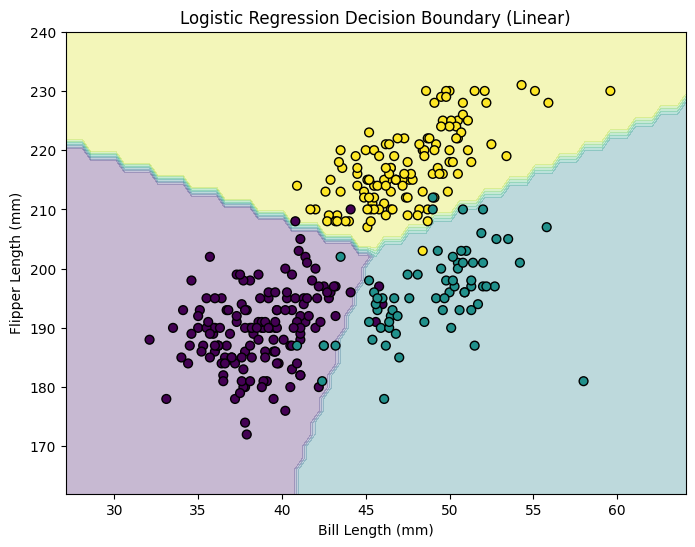

In [7]:
# Task 7: Normal Linear Classification Boundary

# Train Logistic Regression on the same 2-D dataset
log_reg_2d = LogisticRegression(max_iter=1000, random_state=42)
log_reg_2d.fit(X_train_2d, y_train_2d)

plt.figure(figsize=(8, 6))
plot_boundaries(log_reg_2d, X_2d, y_2d, "Logistic Regression Decision Boundary (Linear)")
plt.show()

# Task 8: Compare CART and Normal Linear Boundary

* Plot both the Decision Tree (axis-aligned non-linear) and Logistic Regression (linear) decision boundaries on side-by-side subplots.   * Compare how non-linear CART boundaries differ from straight linear hyperplanes.

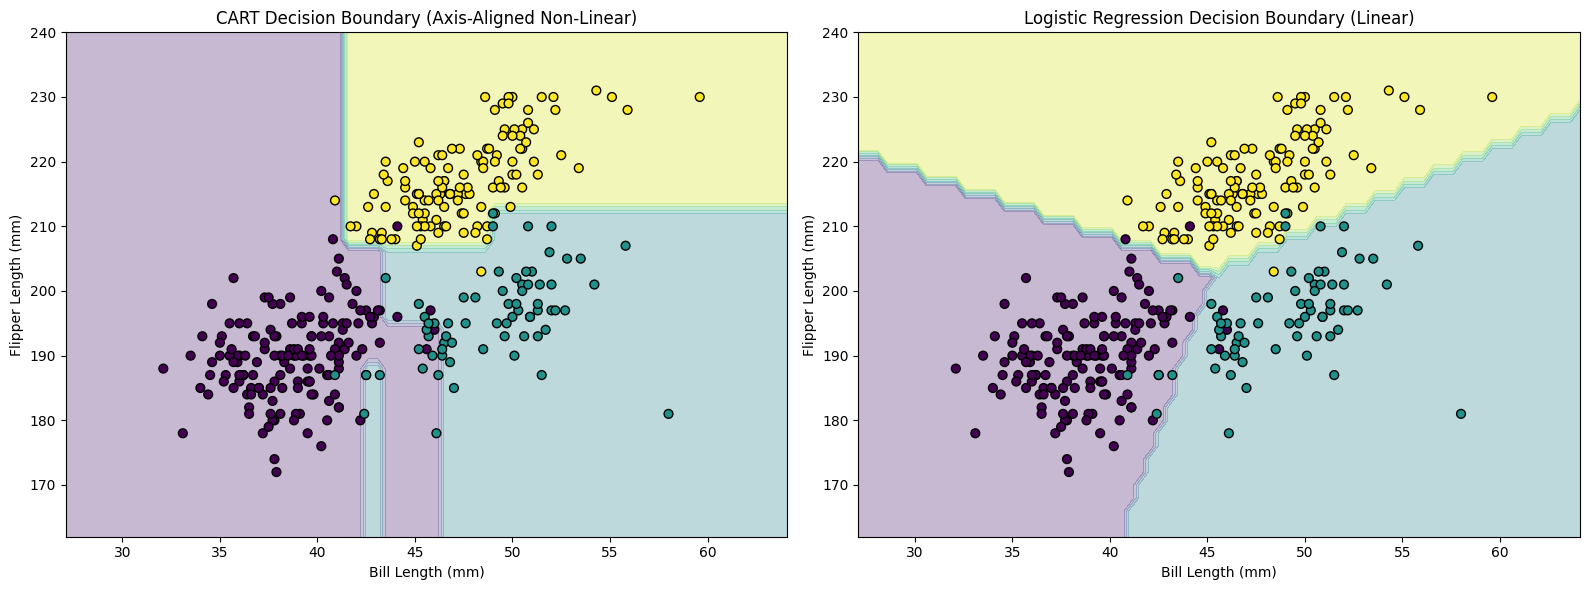

In [8]:
# Task 8: Compare CART and Normal Linear Boundary

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Left subplot - CART Decision Tree
plt.subplot(1, 2, 1)
plot_boundaries(cart_2d, X_2d, y_2d, "CART Decision Boundary (Axis-Aligned Non-Linear)")

# Right subplot - Logistic Regression
plt.subplot(1, 2, 2)
plot_boundaries(log_reg_2d, X_2d, y_2d, "Logistic Regression Decision Boundary (Linear)")

plt.tight_layout()
plt.show()

# Task 9: Compare Performance

* Compare the evaluation metrics (Accuracy, Confusion Matrix, Classification Report) of the CART Classifier vs. Logistic Regression.

In [9]:
# Task 9: Compare Performance

# Evaluate CART 2-D Model
y_pred_cart_2d = cart_2d.predict(X_test_2d)
acc_cart_2d = accuracy_score(y_test_2d, y_pred_cart_2d)

# Evaluate Logistic Regression 2-D Model
y_pred_lr_2d = log_reg_2d.predict(X_test_2d)
acc_lr_2d = accuracy_score(y_test_2d, y_pred_lr_2d)

print("=== Performance Comparison (2-D Models) ===")
print(f"CART 2-D Model Accuracy: {acc_cart_2d:.4f}")
print(f"Logistic Regression 2-D Model Accuracy: {acc_lr_2d:.4f}\n")

print("=== CART Classifier 2-D Report ===")
print(classification_report(y_test_2d, y_pred_cart_2d, target_names=label_encoder.classes_))

print("=== Logistic Regression 2-D Report ===")
print(classification_report(y_test_2d, y_pred_lr_2d, target_names=label_encoder.classes_))

=== Performance Comparison (2-D Models) ===
CART 2-D Model Accuracy: 0.9223
Logistic Regression 2-D Model Accuracy: 0.9806

=== CART Classifier 2-D Report ===
              precision    recall  f1-score   support

      Adelie       0.86      0.98      0.92        45
   Chinstrap       0.94      0.71      0.81        21
      Gentoo       1.00      0.97      0.99        37

    accuracy                           0.92       103
   macro avg       0.93      0.89      0.90       103
weighted avg       0.93      0.92      0.92       103

=== Logistic Regression 2-D Report ===
              precision    recall  f1-score   support

      Adelie       0.98      0.98      0.98        45
   Chinstrap       0.95      0.95      0.95        21
      Gentoo       1.00      1.00      1.00        37

    accuracy                           0.98       103
   macro avg       0.98      0.98      0.98       103
weighted avg       0.98      0.98      0.98       103



# Conclusion

The experiment successfully demonstrated the implementation of the Classification and Regression Tree (CART) algorithm using the Palmer Penguins Extended dataset. The dataset was preprocessed to handle missing values before training. The decision tree structure was visualized, showcasing the hierarchical splits based on feature thresholds. A comparison with a normal linear boundary (Logistic Regression) highlighted CART's ability to create non-linear, axis-aligned decision boundaries to separate different penguin species.